In [258]:
import pandas as pd
import numpy as np
from numpy.random import Generator, PCG64
from joblib import Parallel, delayed
import altair as alt

rng = Generator(PCG64())
alt.renderers.enable("mimetype")
alt.data_transformers.disable_max_rows()

DataTransformerRegistry.enable('default')

In [259]:
# all_df = pd.read_csv(
#     "https://data-visualization-benchmark.s3.us-west-2.amazonaws.com/final-data/all_valid_responses_df.csv",
#     low_memory=False
# )
all_df = pd.read_csv("./dataframes/all_evaluated_responses_df.csv")
all_df = all_df.dropna(subset=['agent_response'])
all_df['item_id'] = all_df['question'] + all_df['image_file']

In [260]:
model_configs = [
    {'model': "Salesforce/blip2-flan-t5-xl", 'top_p': 'p06', 'temp': 't1', 'color': '#5ba3cf', 'accent_color': '#8cbedd'},
    {'model': "Salesforce/blip2-flan-t5-xxl", 'top_p': 'p1', 'temp': 't10', 'color': '#4c78a8', 'accent_color': '#81a0c2'},
    {'model': "llava-hf/llava-1.5-7b-hf", 'top_p': 'p04', 'temp': 't1', 'color': '#f9b574', 'accent_color': '#facb9d'},
    {'model': "llava-hf/llava-1.5-13b-hf", 'top_p': 'p1', 'temp': 't04', 'color': '#f58518', 'accent_color': '#f79d46'},
    {'model': "liuhaotian/llava-v1.6-34b", 'top_p': 'p1', 'temp': 't04', 'color': '#BF9000', 'accent_color': '#F1C232'},
    {'model': "google/pix2struct-chartqa-base", 'top_p': 'p08', 'temp': 't1', 'color': '#ba94c4', 'accent_color': '#c7b8d9'},
    {'model': "google/matcha-chartqa", 'top_p': 'p04', 'temp': 't1', 'color': '#8b6db2', 'accent_color': '#a28ac1'},
    {'model': "GPT-4V", 'top_p': 'p1', 'temp': 't02', 'color': '#c93739', 'accent_color': '#C6765E'},
    {'model': "Human", 'top_p': 'pna', 'temp': 'tna', 'color': '#2e693b', 'accent_color': '#73D287'},
]

### Find Human and Model Performance

In [261]:
def bootstrap_ci(
        data: pd.DataFrame,
        measure: str,
        id_col: str,
        n_iterations=1000,
        statistic=np.mean):
    """Bootstrap confidence interval
    """
    
    items = list(data[id_col].unique())
    n_size = len(items)
    df = data.copy()

    def bootstrap_iteration(data, chosen_items):
        filter_df = pd.concat(
            [data[data['item_id'] == item] for item in chosen_items]
        )
        bs_mean = statistic(filter_df[measure]) 
        return (bs_mean, list(chosen_items))

    qset_means = Parallel(n_jobs=-1)(
        delayed(bootstrap_iteration)(
            df.copy(),
            rng.choice(items, n_size,  replace=True)
        ) for _ in range(n_iterations)
    )
    
    means = []
    qs_used = []
    means = [bs_mean for bs_mean, chosen_qs in qset_means]
 
    # 95% confidence interval
    lower = np.percentile(means, 2.5)
    upper = np.percentile(means, 97.5)
    
    return lower, upper


def create_confidence_interval_df(
    data: pd.DataFrame,
    measure: str, 
    id_col: str,
    condition_col: str,
    statistic=np.mean
):
    data_list = []

    for condition in data[condition_col].unique():
        condition_data = data[data[condition_col] == condition]

        lower, upper = bootstrap_ci(condition_data, measure=measure, statistic=statistic, id_col=id_col)
        mean = statistic(condition_data[measure])

        data_list.append({
            condition_col: condition,
            "ci_upper": upper, 
            "ci_lower": lower,
            "mean": mean
        })

    return pd.DataFrame(data_list)

### Create CI DFs

In [319]:
# def create_invalid_included_df():
#     items = all_df['item_id'].unique()

#     grouped_all_items = []
#     for item in items:
#         for agent, group in all_df[all_df['item_id'] == item].groupby(['agent_type']):
#             num_invalid_items = len(group) - 10 # check for missing items
#             if num_invalid_items < 0:
#                 # if missing add N rows marked as incorrect
#                 invalid_rows_df = pd.DataFrame([{
#                     'item_id': item, 
#                     'is_correct': 0,
#                     'agent_type': agent[0],
#                     'test_type': group.iloc[0]['test_type']
#                 } for _ in range(abs(num_invalid_items))])
    
#                 complete_group = pd.concat([invalid_rows_df, group])
#                 grouped_all_items.append(complete_group)
#             else:
#                 grouped_all_items.append(group)
    
#     invalid_included_df = pd.concat(grouped_all_items)
#     return invalid_included_df

def create_invalid_included_df():
    item_test_tuples = all_df[['item_id', 'test_type']].drop_duplicates().itertuples(index=False)

    grouped_all_items = []
    for item, test_type in item_test_tuples:
        for agent, agent_group in all_df.groupby(['agent_type']):
            if item in agent_group['item_id'].unique():
                group = agent_group[agent_group['item_id'] == item]
            else:
                group = pd.DataFrame(
                    {}, 
                    columns=['item_id', 'is_correct', 'agent_type', 'test_type']
                )
                
            num_invalid_items = len(group) - 10 # check for missing items
            
            if num_invalid_items < 0:
                # if missing add N rows marked as incorrect
                invalid_rows_df = pd.DataFrame([{
                    'item_id': item, 
                    'is_correct': 0,
                    'agent_type': agent[0],
                    'test_type': test_type
                } for _ in range(abs(num_invalid_items))])
    
                complete_group = pd.concat([invalid_rows_df, group])
                grouped_all_items.append(complete_group)
            else:
                grouped_all_items.append(group)
    
    invalid_included_df = pd.concat(grouped_all_items)
    return invalid_included_df

def create_ci_df(all_df, invalid_included_df):
    ci_dfs = []
    
    for test in all_df['test_type'].unique():
        invalid_inclusive_ci_df = create_confidence_interval_df(
            data=invalid_included_df[invalid_included_df['test_type'] == test].copy(),
            measure='is_correct', 
            id_col='item_id',
            condition_col='agent_type',
        )
        invalid_inclusive_ci_df['test_type'] = test
        invalid_inclusive_ci_df['scoring_type'] = 'all'
    
        valid_ci_df = create_confidence_interval_df(
            data=all_df[all_df['test_type'] == test].copy(),
            measure='is_correct', 
            id_col='item_id',
            condition_col='agent_type',
            statistic=np.mean
        )
        valid_ci_df['test_type'] = test
        valid_ci_df['scoring_type'] = 'valid_only'
    
        ci_dfs.append(invalid_inclusive_ci_df)
        ci_dfs.append(valid_ci_df)
    
    ci_dfs = pd.concat(ci_dfs)
    
    return ci_dfs

try:
    ci_dfs = pd.read_csv("./dataframes/performance_ci_df.csv")
    invalid_included_df = create_invalid_included_df()
except:
    invalid_included_df = create_invalid_included_df()
    ci_dfs = create_ci_df(all_df, invalid_included_df)
    ci_dfs.to_csv("./dataframes/performance_ci_df.csv")
    invalid_included_df.to_csv("./dataframes/invalid_included_df.csv")

In [320]:
invalid_included_df.groupby('agent_type').size()

agent_type
GPT-4V                             8510
Human                             99256
Salesforce/blip2-flan-t5-xl        8510
Salesforce/blip2-flan-t5-xxl       8510
google/matcha-chartqa              8510
google/pix2struct-chartqa-base     8510
liuhaotian/llava-v1.6-34b          8510
llava-hf/llava-1.5-13b-hf          8510
llava-hf/llava-1.5-7b-hf           8510
dtype: int64

In [321]:
all_df.groupby('agent_type').size()

agent_type
GPT-4V                             5288
Human                             98848
Salesforce/blip2-flan-t5-xl        7040
Salesforce/blip2-flan-t5-xxl       6926
google/matcha-chartqa              7082
google/pix2struct-chartqa-base     6385
liuhaotian/llava-v1.6-34b          2735
llava-hf/llava-1.5-13b-hf          3202
llava-hf/llava-1.5-7b-hf           3964
dtype: int64

### Create CI Plot

In [322]:
def create_error_plot(ci_df, test_name):
    """ Creates a scatter plot with error bars for accuracy data.

    Args:
        test: name of the test
    """
    model_order = [c['model'] for c in model_configs]
    main_color_order = [c['color'] for c in model_configs]
    bg_color_order = [c['accent_color'] for c in model_configs]

    ytitle = ''
    y_domain = [0, 1]
    opacity = 1
  

    error_bars = alt.Chart(ci_df).mark_errorbar().encode(
        x=alt.X("agent_type:N"),
        y=alt.Y("ci_upper", title=ytitle),
        y2=alt.Y2("ci_lower"),
        xOffset="scoring_type:N",
        strokeWidth=alt.value(2),
        color=alt.Color('agent_type', scale=alt.Scale(domain=model_order, range=main_color_order)).legend(None)
    )

    mean_point_plot_filled = alt.Chart(
        ci_df, 
        title=test_name
    ).mark_point(
        size=40, 
        filled=True,
        strokeWidth=1,
        opacity=1
    ).encode(
        y=alt.Y("mean:Q", scale=alt.Scale(domain=[0, 1])),
        x=alt.X("agent_type:N", scale=alt.Scale(domain=model_order), title=None),
        xOffset="scoring_type:N",
        stroke=alt.Stroke(
            'agent_type:N', 
            scale=alt.Scale(
                domain=model_order, 
                range=main_color_order
            )
        ).legend(None),
        color=alt.condition(
            alt.datum['scoring_type'] == 'all',
            alt.value('white'),  # Use white color if group_includes is 'all'
            alt.Color(
                'agent_type:N', 
                scale=alt.Scale(
                    domain=model_order, 
                    range=main_color_order
                )
            )
        ).legend(None),
    )
    
    mean_slope_plot = alt.Chart(ci_df, title=test_name).mark_line(
        strokeWidth=2,
        opacity=0.6
    ).encode(
        y=alt.Y("mean:Q",scale=alt.Scale(domain=[0, 1])),
        x=alt.X("agent_type:N", scale=alt.Scale(domain=model_order), title=None),
        xOffset="scoring_type:N",
        # detail='scoring_type',
        color=alt.Color(
            'agent_type:N', 
            scale=alt.Scale(
                domain=model_order, 
                range=main_color_order
            )
        ).legend(None),
    )

    final_plot = error_bars + mean_slope_plot + mean_point_plot_filled # + mean_point_plot_filled 
    
    return final_plot.resolve_scale(color="independent",  opacity="independent")

In [323]:
# ci_dfs

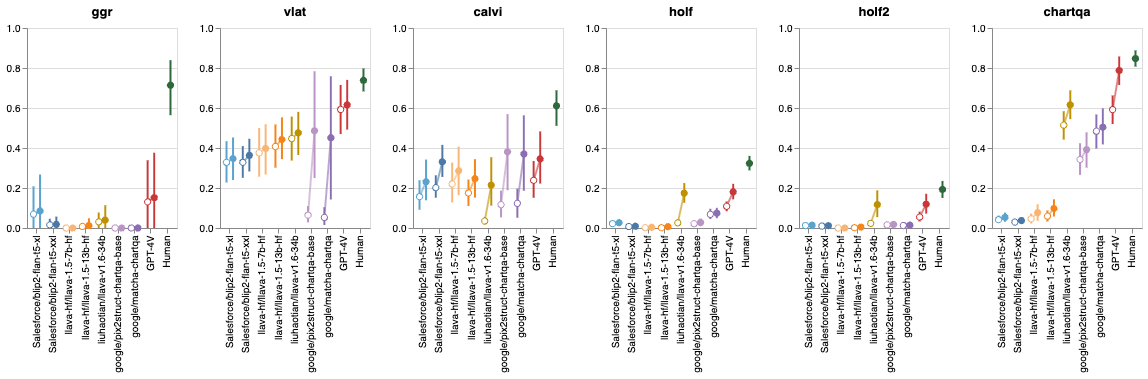

In [325]:
ci_df = ci_dfs[
    ((ci_dfs['scoring_type'] == 'valid_only') &
    (ci_dfs['agent_type'] == 'Human')) |
    (ci_dfs['agent_type'] != 'Human')
]


tests = ['ggr', 'vlat', 'calvi', 'holf', 'holf2',
       'chartqa-test-continuous-human']

plots = []
for test in tests:
    test_ci_df = ci_df[ci_df['test_type'] == test]
    if len(test) > 6:
        test = test[:7]
    
    plot = create_error_plot(test_ci_df, test)
    plot = plot.properties(width=150, height=200)
    plots.append(plot)

plots = alt.hconcat(*plots)
plots.save("./figures/human_machine_performance.pdf")
plots

## Check regression values

### Load R

In [347]:
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


In [348]:
%%R
install.packages("lme4")
library(lme4)


The downloaded binary packages are in
	/var/folders/v8/3zpbxkws53b3x6m8509jyml80000gn/T//Rtmpcu06Qu/downloaded_packages


trying URL 'https://cran.case.edu/bin/macosx/big-sur-arm64/contrib/4.4/lme4_1.1-36.tgz'
Content type 'application/x-gzip' length 7079300 bytes (6.8 MB)
downloaded 6.8 MB



### Regression Model

In [336]:
model_only_df = all_df[all_df['agent_type'] != 'Human']

In [337]:
%%R -i model_only_df

control <- glmerControl(
    optimizer = "bobyqa",
    optCtrl = list(maxfun = 2e5)
)

null_model <- glmer(
    is_correct ~ 1 + (1 | item_id), 
    data = model_only_df, 
    family = binomial, 
    control = control
)

### Do models reliably differ in overall performance from one another?

In [338]:
print("Num unique models: ", model_only_df['agent_type'].nunique())

Num unique models:  8


In [339]:
%%R -i model_only_df

agent_model <- glmer(
    is_correct ~ agent_type + (1 | item_id), 
    data = model_only_df, 
    family = binomial,
    control = control
)

anova(null_model, agent_model, test="LRT")

Data: model_only_df
Models:
null_model: is_correct ~ 1 + (1 | item_id)
agent_model: is_correct ~ agent_type + (1 | item_id)
            npar   AIC   BIC   logLik deviance Chisq Df Pr(>Chisq)    
null_model     2 23594 23611 -11795.0    23590                        
agent_model    9 20017 20095  -9999.5    19999  3591  7  < 2.2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


### Model / Human performance gap across assessment

In [340]:
best_performing_models = ci_df[
    (ci_df['scoring_type'] == 'valid_only') &
    (ci_df['agent_type'] != 'Human')
]
best_performing_models = best_performing_models.sort_values(by=['test_type', 'mean',]).groupby('test_type').last().reset_index()
best_performing_models

,test_type,agent_type,ci_upper,ci_lower,mean,scoring_type
0,calvi,google/pix2struct-chartqa-base,0.569360,0.189002,0.380435,valid_only
1,chartqa-test-continuous-human,GPT-4V,0.857495,0.714922,0.787234,valid_only
2,ggr,GPT-4V,0.376226,0.000000,0.151786,valid_only
3,holf,GPT-4V,0.220796,0.143398,0.180718,valid_only
4,holf2,GPT-4V,0.170888,0.072647,0.119119,valid_only
5,vlat,GPT-4V,0.740404,0.492260,0.615686,valid_only


In [341]:
best_model_human_df = []
best_performing_models_dict = best_performing_models[['agent_type', 'test_type']].to_dict(orient='records')
for record in best_performing_models_dict:
    agent_type = record['agent_type']
    test_type = record['test_type']
    
    best_model_human_df.append(model_only_df[
        (model_only_df['agent_type'] == agent_type) &
        (model_only_df['test_type'] == test_type)
    ])

best_model_human_df = pd.concat(best_model_human_df)
best_model_human_df = best_model_human_df.groupby(['item_id', 'test_type'])['is_correct'].mean().reset_index()
best_model_human_df['agent_type'] = 'best_model'

human_only_df =  all_df[all_df['agent_type'] == 'Human'].copy()
human_only_df = human_only_df.groupby(['item_id', 'test_type'])['is_correct'].mean().reset_index()
human_only_df['agent_type'] = 'Human'

best_model_human_df = pd.concat([best_model_human_df, human_only_df])

In [342]:
# best_model_human_df


In [ ]:
# %%R -i best_model_human_df

# null_model <- lmer(
#     is_correct ~ 1 + agent_type + (1 | item_id), 
#     data = best_model_human_df, 
#     family = binomial, 
#     control = control
# )

# agent_model <- lmer(
#     is_correct ~ 1 + agent_type + (1 | item_id), 
#     data = best_model_human_df, 
#     family = binomial, 
#     control = control
# )

In [349]:
# %%R -i best_model_human_df

# control <- glmerControl(
#     optimizer = "bobyqa",
#     optCtrl = list(maxfun = 2e5)
# )

# null_model <- lmer(
#     is_correct ~ 1 + (1 | item_id), 
#     data = model_only_df, 
#     family = binomial, 
#     control = control
# )

# agent_model <- lmer(

# )

In [350]:
# human_model_correlation_df

In [351]:
%%R -i human_model_correlation_df

base_model <- lmer(
    correlation ~ 1 + (1 | item_id) , 
    data = human_model_correlation_df,
)

interaction_model <- lmer(
    correlation ~ 1 + model * test + , 
    data = human_model_correlation_df, 
)

anova(base_model, interaction_model, test="LRT")
# anova(null_model, agent_model, test="LRT")

NameError: name 'human_model_correlation_df' is not defined.

In [ ]:
# all_df['item_id']

### Is human-model gap was smaller for misleading items in CALVI?

In [352]:
calvi_human_gpt_df = all_df[
    (all_df['agent_type'].isin(['Human', 'GPT-4V']))
    & (all_df['test_type'] == 'calvi')
].copy()
calvi_human_gpt_df['misleading_type'] = calvi_human_gpt_df['image_file'].apply(lambda f : f[0])

In [353]:
%%R -i calvi_human_gpt_df

null_model <- glmer(
    is_correct ~ 1 + (1 | item_id), 
    data = calvi_human_gpt_df, 
    family = binomial, 
    control = control
)

agent_model <- glmer(
    is_correct ~ misleading_type + (1 | item_id), 
    data = calvi_human_gpt_df, 
    family = binomial,
    control = control
)

anova(null_model, agent_model, test="LRT")

Data: calvi_human_gpt_df
Models:
null_model: is_correct ~ 1 + (1 | item_id)
agent_model: is_correct ~ misleading_type + (1 | item_id)
            npar   AIC   BIC  logLik deviance  Chisq Df Pr(>Chisq)    
null_model     2 13183 13198 -6589.4    13179                         
agent_model    3 13161 13184 -6577.4    13155 23.971  1  9.779e-07 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


## Difference of means

In [354]:
def bootstrap_diff_of_mean_ci(
        data: pd.DataFrame,
        measure,
        id_col,
        group1: str,
        group2: str,
        group_col='agent_type',
        n_iterations=1000,
        statistic=np.mean,
    ):
    
    items = list(data[id_col].unique())
    n_size = len(items)
    df = data.copy()

    def bootstrap_iteration(data, chosen_items):
        filter_df = pd.concat(
            [data[data[id_col].isin([item])] for item in chosen_items]
        )
        
        bs_mean = statistic(filter_df[measure]) 
        return (bs_mean, list(chosen_items))

    
    qset_means1 = Parallel(n_jobs=-1)(
        delayed(bootstrap_iteration)(
            df[df[group_col] == group1].copy(),
            rng.choice(items, n_size,  replace=True)
        ) for _ in range(n_iterations)
    )

    qset_means2 = Parallel(n_jobs=-1)(
        delayed(bootstrap_iteration)(
            df[df[group_col] == group2].copy(),
            rng.choice(items, n_size,  replace=True)
        ) for _ in range(n_iterations)
    )
    
    means = []
    qs_used = []
    means1 = [bs_mean for bs_mean, chosen_qs in qset_means1]
    means2 = [bs_mean for bs_mean, chosen_qs in qset_means2]
    means = np.subtract(means1, means2)
 
    # 95% confidence interval
    lower = np.percentile(means, 2.5)
    upper = np.percentile(means, 97.5)
    
    return lower, upper

def create_diff_of_mean_ci_df(
    data: pd.DataFrame,
    measure,
    id_col,
    group1,
    group2,
    group_col='agent_type',
    statistic=np.mean
):
    """ create the dataframe for 95% bootstrapped confidence interval
    data: dataset
    measure: dependent variable
    id_col: units to bootstrap along (e.g. participant_d or item_id)
    condition_col: the different conditions of the experiments
    """
    
    data_list = []
    lower, upper = bootstrap_diff_of_mean_ci(
        data,
        group1=group1,
        group2=group2,
        measure=measure, 
        statistic=statistic,
        group_col=group_col,
        id_col=id_col)
    
    mean1 = data[data[group_col] == group1][measure].mean()
    mean2 = data[data[group_col] == group2][measure].mean()
    mean = mean1 - mean2
    
    data_list.append({
        "mean": mean,
        "ci_upper": upper, 
        "ci_lower": lower,
    })

    return pd.DataFrame(data_list)

### Difference of means between Valid vs invalid

In [355]:
# model_invalid_inclded

In [356]:
model_valid_only = all_df[all_df['agent_type'] != 'Human'].copy()
model_valid_only['response_type'] = 'valid_only'
model_invalid_inclded = invalid_included_df[invalid_included_df['agent_type'] != 'Human'].copy()
model_invalid_inclded['response_type'] = 'invalid_included'
model_response_type_df = pd.concat([model_invalid_inclded, model_valid_only])
model_response_type_df['test_type'] = model_response_type_df['test_type'].apply(
    lambda t : 'mc' if t in ['ggr', 'vlat', 'calvi'] else 'num'
)

In [357]:
## multiple choice items
model_response_type_mc_df = create_diff_of_mean_ci_df(
    model_response_type_df[model_response_type_df['test_type'] == 'mc'],
    measure='is_correct',
    id_col='item_id',
    group1='valid_only',
    group2='invalid_included',
    group_col='response_type',
)
model_response_type_mc_df

,mean,ci_upper,ci_lower
0,0.121989,0.180124,0.06438


In [358]:
## numerical items
model_response_type_num_df = create_diff_of_mean_ci_df(
    model_response_type_df[model_response_type_df['test_type'] == 'num'],
    measure='is_correct',
    id_col='item_id',
    group1='valid_only',
    group2='invalid_included',
    group_col='response_type',
)
model_response_type_num_df

,mean,ci_upper,ci_lower
0,0.040537,0.05698,0.024044


### Difference of means between GPT-4V and other models

In [359]:
gpt_vs_model_df = all_df[all_df['agent_type'] != 'Human'].copy()
gpt_vs_model_df['agent_type'] = gpt_vs_model_df['agent_type'].apply(
    lambda a : "model" if a != 'GPT-4V' else 'GPT-4V'
)
gpt_vs_model_df['test_type'] = gpt_vs_model_df['test_type'].apply(
    lambda t : 'mc' if t in ['ggr', 'vlat', 'calvi'] else 'num'
)

In [360]:
## multiple choice items
gpt_model_mc_df = create_diff_of_mean_ci_df(
    gpt_vs_model_df[gpt_vs_model_df['test_type'] == 'mc'],
    measure='is_correct',
    id_col='item_id',
    group1='GPT-4V',
    group2='model'
)
gpt_model_mc_df

,mean,ci_upper,ci_lower
0,0.143466,0.244113,0.044385


In [361]:
## numerical response items
gpt_model_num_df = create_diff_of_mean_ci_df(
    gpt_vs_model_df[gpt_vs_model_df['test_type'] == 'num'],
    measure='is_correct',
    id_col='item_id',
    group1='GPT-4V',
    group2='model'
)
gpt_model_num_df

,mean,ci_upper,ci_lower
0,0.218168,0.259551,0.177394


### Difference of means between Humans and GPT-4V

In [362]:
# all_df

In [363]:
human_vs_model_df = all_df[all_df['agent_type'].isin(['GPT-4V', 'Human'])].copy()
human_vs_model_df['test_type'] = human_vs_model_df['test_type'].apply(
    lambda t : 'mc' if t in ['ggr', 'vlat', 'calvi'] else 'num'
)

In [364]:
## multiple choice items
human_model_mc_df = create_diff_of_mean_ci_df(
    human_vs_model_df[human_vs_model_df['test_type'] == 'mc'],
    measure='is_correct',
    id_col='item_id',
    group1='GPT-4V',
    group2='Human'
)
human_model_mc_df

,mean,ci_upper,ci_lower
0,-0.256266,-0.154076,-0.349764


In [365]:
## numerical response items
human_model_num_df = create_diff_of_mean_ci_df(
    human_vs_model_df[human_vs_model_df['test_type'] == 'num'],
    measure='is_correct',
    id_col='item_id',
    group1='GPT-4V',
    group2='Human'
)
human_model_num_df

,mean,ci_upper,ci_lower
0,0.001627,0.049752,-0.047823


### Difference of means between best performing mode and humans

In [366]:
all_df['test_type'].unique()

array(['ggr', 'vlat', 'calvi', 'holf', 'holf2',
       'chartqa-test-continuous-human'], dtype=object)

In [367]:
all_df['agent_type'].unique()

array(['Salesforce/blip2-flan-t5-xl', 'Salesforce/blip2-flan-t5-xxl',
       'llava-hf/llava-1.5-7b-hf', 'llava-hf/llava-1.5-13b-hf',
       'liuhaotian/llava-v1.6-34b', 'google/pix2struct-chartqa-base',
       'google/matcha-chartqa', 'GPT-4V', 'Human'], dtype=object)

In [368]:
human_vs_model_df_ggr = all_df[
    (all_df['agent_type'].isin(['GPT-4V', 'Human'])) &
    (all_df['test_type'] == 'ggr')
].copy()

create_diff_of_mean_ci_df(
    human_vs_model_df_ggr,
    measure='is_correct',
    id_col='item_id',
    group1='GPT-4V',
    group2='Human'
)

,mean,ci_upper,ci_lower
0,-0.562198,-0.297047,-0.77527


In [369]:
human_vs_model_df_vlat = all_df[
    (all_df['agent_type'].isin(['GPT-4V', 'Human'])) &
    (all_df['test_type'] == 'vlat')
].copy()

create_diff_of_mean_ci_df(
    human_vs_model_df_vlat,
    measure='is_correct',
    id_col='item_id',
    group1='GPT-4V',
    group2='Human'
)

,mean,ci_upper,ci_lower
0,-0.1228,0.003174,-0.260456


In [370]:
# human_vs_model_df_calvi

In [371]:
agent = 'google/pix2struct-chartqa-base'
human_vs_model_df_calvi = all_df[
    (all_df['agent_type'].isin([agent, 'Human'])) &
    (all_df['test_type'] == 'calvi')
].copy()

create_diff_of_mean_ci_df(
    human_vs_model_df_calvi,
    measure='is_correct',
    id_col='item_id',
    group1=agent,
    group2='Human'
)

,mean,ci_upper,ci_lower
0,-0.230182,-0.002137,-0.423382


In [372]:
agent = 'Salesforce/blip2-flan-t5-xl'
human_vs_model_df_holf = all_df[
    (all_df['agent_type'].isin([agent, 'Human'])) &
    (all_df['test_type'] == 'holf')
].copy()

create_diff_of_mean_ci_df(
    human_vs_model_df_holf,
    measure='is_correct',
    id_col='item_id',
    group1=agent,
    group2='Human'
)

,mean,ci_upper,ci_lower
0,-0.297129,-0.258505,-0.334804


In [373]:
agent = 'google/matcha-chartqa'
human_vs_model_df_holf = all_df[
    (all_df['agent_type'].isin([agent, 'Human'])) &
    (all_df['test_type'] == 'holf2')
].copy()

create_diff_of_mean_ci_df(
    human_vs_model_df_holf,
    measure='is_correct',
    id_col='item_id',
    group1=agent,
    group2='Human'
)

,mean,ci_upper,ci_lower
0,-0.17952,-0.137038,-0.222991


In [374]:
human_vs_model_df_cqa = all_df[
    (all_df['agent_type'].isin(['GPT-4V', 'Human'])) &
    (all_df['test_type'] == 'chartqa-test-continuous-human')
].copy()

create_diff_of_mean_ci_df(
    human_vs_model_df_cqa,
    measure='is_correct',
    id_col='item_id',
    group1='GPT-4V',
    group2='Human'
)

,mean,ci_upper,ci_lower
0,-0.059966,0.02164,-0.146398


### CALVI difference of means between GPT-4V and Humans

In [375]:
ci_df[
    (ci_df['test_type'] == 'calvi') &
    (ci_df['scoring_type'] == 'valid_only')
].sort_values(by='mean')

,agent_type,ci_upper,ci_lower,mean,test_type,scoring_type
4,liuhaotian/llava-v1.6-34b,0.353568,0.111892,0.214286,calvi,valid_only
0,Salesforce/blip2-flan-t5-xl,0.341945,0.138608,0.231527,calvi,valid_only
3,llava-hf/llava-1.5-13b-hf,0.344186,0.151564,0.247059,calvi,valid_only
2,llava-hf/llava-1.5-7b-hf,0.406383,0.164502,0.285714,calvi,valid_only
1,Salesforce/blip2-flan-t5-xxl,0.415467,0.255555,0.330601,calvi,valid_only
7,GPT-4V,0.482606,0.222445,0.345411,calvi,valid_only
6,google/matcha-chartqa,0.563115,0.186244,0.370000,calvi,valid_only
5,google/pix2struct-chartqa-base,0.569360,0.189002,0.380435,calvi,valid_only
8,Human,0.688494,0.510930,0.610616,calvi,valid_only


In [376]:
calvi_gpt_human_df = all_df[
    (all_df['test_type'] == 'calvi') &
    (all_df['agent_type'].isin(['GPT-4V', 'Human']))
].copy()
calvi_gpt_human_df['misleading_type'] = calvi_gpt_human_df['image_file'].apply(lambda f : f[0])

In [377]:
human_model_num_df = create_diff_of_mean_ci_df(
    calvi_gpt_human_df[calvi_gpt_human_df['misleading_type'] == 'N'],
    measure='is_correct',
    id_col='item_id',
    group1='GPT-4V',
    group2='Human'
)
human_model_num_df

,mean,ci_upper,ci_lower
0,-0.317787,-0.005618,-0.611889


In [378]:
human_model_num_df = create_diff_of_mean_ci_df(
    calvi_gpt_human_df[calvi_gpt_human_df['misleading_type'] == 'T'],
    measure='is_correct',
    id_col='item_id',
    group1='GPT-4V',
    group2='Human'
)
human_model_num_df

,mean,ci_upper,ci_lower
0,-0.076499,0.09571,-0.23138


DO this for pix2struct -- best performing model for calvi

In [379]:
calvi_gpt_human_df = all_df[
    (all_df['test_type'] == 'calvi') &
    (all_df['agent_type'].isin(['google/pix2struct-chartqa-base', 'Human']))
].copy()
calvi_gpt_human_df['misleading_type'] = calvi_gpt_human_df['image_file'].apply(lambda f : f[0])

In [380]:
human_model_num_df = create_diff_of_mean_ci_df(
    calvi_gpt_human_df[calvi_gpt_human_df['misleading_type'] == 'N'],
    measure='is_correct',
    id_col='item_id',
    group1='google/pix2struct-chartqa-base',
    group2='Human'
)
human_model_num_df

,mean,ci_upper,ci_lower
0,-0.428239,NaN,NaN


In [381]:
human_model_num_df = create_diff_of_mean_ci_df(
    calvi_gpt_human_df[calvi_gpt_human_df['misleading_type'] == 'T'],
    measure='is_correct',
    id_col='item_id',
    group1='google/pix2struct-chartqa-base',
    group2='Human'
)
human_model_num_df

,mean,ci_upper,ci_lower
0,-0.012465,0.215944,-0.238813


In [382]:
all_df[all_df[] == '']

SyntaxError: invalid syntax. Perhaps you forgot a comma? (1348908125.py, line 1)